# RoadVision AI — Détection de véhicules avec YOLOv9-C et GELAN-C

Notebook corrigé pour Kaggle. Il utilise le dépôt officiel **WongKinYiu/yolov9**, prépare un dataset `train/val/test`, entraîne YOLOv9-C et GELAN-C, puis évalue les deux modèles sur le jeu `test`.

**Important :** active un accélérateur GPU dans Kaggle (Settings → Accelerator → GPU). Exécute les cellules dans l’ordre. La première exécution peut être longue.


## 1. Installation des dépendances

In [1]:
# %pip install -q kagglehub pyyaml pandas matplotlib pillow seaborn thop requests

## 2. Imports, reproductibilité et chemins

In [2]:
import os, sys, json, math, random, shutil, subprocess, time
from pathlib import Path
from collections import Counter

import kagglehub
import yaml
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "0" if torch.cuda.is_available() else "cpu"
IMG_SIZE = 640
BATCH_SIZE = 4
WORKERS = 2
EPOCHS_TRANSFER = 5
EPOCHS_FINETUNE = 15
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

REPO = Path("/kaggle/working/yolov9")
WORK_ROOT = Path("/kaggle/working/roadvision_native")
# Dataset reconstruit dans un dossier séparé : aucune ancienne donnée ne sera mélangée.
DATASET_ROOT = WORK_ROOT / "dataset_rebuilt"
RUNS_ROOT = WORK_ROOT / "runs"
EVAL_ROOT = WORK_ROOT / "evaluation"

for folder in [WORK_ROOT, RUNS_ROOT, EVAL_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)

print("Python :", sys.version)
print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
print("Device :", DEVICE)
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))


Python : 3.10.22 | packaged by conda-forge | (main, Oct  6 2026, 23:02:24) [GCC 14.4.0]
PyTorch : 2.14.1+cu130
CUDA disponible : False
Device : cpu


/venv/main/lib/python3.10/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12080). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


## 3. Télécharger et localiser le dataset

In [3]:
DATASET_ID = "ashfakyeafi/road-vehicle-images-dataset"
DATASET_DOWNLOAD_PATH = Path(kagglehub.dataset_download(DATASET_ID))
matches = list(DATASET_DOWNLOAD_PATH.rglob("trafic_data"))
if not matches:
    raise FileNotFoundError(f"Dossier trafic_data introuvable dans {DATASET_DOWNLOAD_PATH}")

SOURCE_DATASET = matches[0]
print("Dataset source :", SOURCE_DATASET)

required_dirs = [
    SOURCE_DATASET / "train/images",
    SOURCE_DATASET / "train/labels",
    SOURCE_DATASET / "valid/images",
    SOURCE_DATASET / "valid/labels",
]
for folder in required_dirs:
    if not folder.is_dir():
        raise FileNotFoundError(f"Dossier manquant : {folder}")


Dataset source : /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data


## 4. Cloner le dépôt officiel YOLOv9

In [4]:
REPO_URL = "https://github.com/WongKinYiu/yolov9.git"
if not REPO.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
else:
    print("Dépôt déjà présent :", REPO)

required_repo_files = [
    "train_dual.py", "train.py", "val_dual.py", "val.py",
    "models/detect/yolov9-c.yaml", "models/detect/gelan-c.yaml",
    "data/hyps/hyp.scratch-high.yaml",
]
missing = [f for f in required_repo_files if not (REPO / f).is_file()]
if missing:
    raise FileNotFoundError("Fichiers YOLOv9 manquants : " + ", ".join(missing))
os.chdir(REPO)
print("Version Git :", subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"], cwd=REPO, text=True
).strip())


Dépôt déjà présent : /kaggle/working/yolov9
Version Git : 5b1ea9a


## 5. Télécharger les poids préentraînés

In [5]:
import requests

weights = {
    "yolov9-c.pt": "https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-c.pt",
    "gelan-c.pt": "https://github.com/WongKinYiu/yolov9/releases/download/v0.1/gelan-c.pt",
}
for filename, url in weights.items():
    destination = REPO / filename
    if destination.exists() and destination.stat().st_size > 0:
        print("Déjà présent :", filename)
        continue
    print("Téléchargement :", filename)
    response = requests.get(url, stream=True, timeout=180)
    response.raise_for_status()
    with open(destination, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)
    if destination.stat().st_size == 0:
        raise RuntimeError(f"Téléchargement vide : {filename}")
    print("OK :", destination, destination.stat().st_size, "bytes")


Déjà présent : yolov9-c.pt
Téléchargement : gelan-c.pt
OK : /kaggle/working/yolov9/gelan-c.pt 51508261 bytes


## 6. Charger la configuration des classes

In [6]:
yaml_candidates = [
    SOURCE_DATASET.parent / "data_1.yaml",
    SOURCE_DATASET / "data_1.yaml",
    DATASET_DOWNLOAD_PATH / "data_1.yaml",
]
SOURCE_YAML = next((p for p in yaml_candidates if p.is_file()), None)
if SOURCE_YAML is None:
    found = list(DATASET_DOWNLOAD_PATH.rglob("data_1.yaml"))
    if not found:
        raise FileNotFoundError("data_1.yaml introuvable dans le dataset.")
    SOURCE_YAML = found[0]

with open(SOURCE_YAML, encoding="utf-8") as f:
    source_config = yaml.safe_load(f)

CLASS_NAMES = source_config["names"]
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[k] for k in sorted(CLASS_NAMES, key=lambda x: int(x))]
NC = int(source_config.get("nc", len(CLASS_NAMES)))
assert NC == len(CLASS_NAMES), "nc ne correspond pas au nombre de classes."
assert len(set(CLASS_NAMES)) == NC, "Noms de classes dupliqués."

print("YAML source :", SOURCE_YAML)
print("Nombre de classes :", NC)
for i, name in enumerate(CLASS_NAMES):
    print(f"{i:02d}: {name}")


YAML source : /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/data_1.yaml
Nombre de classes : 21
00: ambulance
01: army vehicle
02: auto rickshaw
03: bicycle
04: bus
05: car
06: garbagevan
07: human hauler
08: minibus
09: minivan
10: motorbike
11: pickup
12: policecar
13: rickshaw
14: scooter
15: suv
16: taxi
17: three wheelers -CNG-
18: truck
19: van
20: wheelbarrow


## 7. Auditer les images et annotations source

In [7]:
def is_valid_yolo_line(line):
    parts = line.strip().split()
    if len(parts) != 5:
        return False
    try:
        class_id = int(parts[0])
        x, y, w, h = map(float, parts[1:])
    except (ValueError, OverflowError):
        return False
    vals = [x, y, w, h]
    return (
        0 <= class_id < NC
        and all(math.isfinite(v) for v in vals)
        and all(0 <= v <= 1 for v in vals)
        and w > 0 and h > 0
        and x - w/2 >= -1e-6 and x + w/2 <= 1 + 1e-6
        and y - h/2 >= -1e-6 and y + h/2 <= 1 + 1e-6
    )

def collect_records(split_name):
    images_dir = SOURCE_DATASET / split_name / "images"
    labels_dir = SOURCE_DATASET / split_name / "labels"
    image_paths = sorted(
        p for p in images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    records, stats = [], Counter()
    label_stems = {p.stem for p in labels_dir.glob("*.txt")}
    image_stems = {p.stem for p in image_paths}
    stats["images"] = len(image_paths)
    stats["labels_without_image"] = len(label_stems - image_stems)

    for image_path in image_paths:
        label_path = labels_dir / f"{image_path.stem}.txt"
        if not label_path.is_file():
            raise FileNotFoundError(f"Label manquant : {label_path}")
        try:
            with Image.open(image_path) as im:
                im.verify()
        except (OSError, UnidentifiedImageError):
            stats["unreadable_images"] += 1
            continue
        try:
            raw_lines = label_path.read_text(encoding="utf-8").splitlines()
        except (OSError, UnicodeError):
            stats["unreadable_labels"] += 1
            continue

        valid_lines, invalid = [], 0
        for line in raw_lines:
            if not line.strip():
                continue
            if is_valid_yolo_line(line):
                valid_lines.append(line.strip())
            else:
                invalid += 1
        stats["invalid_lines"] += invalid
        stats["files_with_invalid_lines"] += int(invalid > 0)
        stats["images_without_objects"] += int(len(valid_lines) == 0)
        records.append({
            "image": image_path,
            "labels": valid_lines,
            "source_split": split_name
        })
    return records, stats

train_records, train_stats = collect_records("train")
valid_records, valid_stats = collect_records("valid")
for label, stats in [("TRAIN", train_stats), ("VALID", valid_stats)]:
    print("\n", label)
    for key, value in sorted(stats.items()):
        print(f"{key}: {value}")
all_records = train_records + valid_records
print("\nTotal images utilisables :", len(all_records))



 TRAIN
files_with_invalid_lines: 0
images: 2704
images_without_objects: 2
invalid_lines: 0
labels_without_image: 0

 VALID
files_with_invalid_lines: 2
images: 300
images_without_objects: 2
invalid_lines: 24
labels_without_image: 0

Total images utilisables : 3004


## 8. Reconstruire un dataset propre en train / val / test

In [8]:
# Recréation propre du dossier cible à chaque exécution : évite les fichiers résiduels.
if DATASET_ROOT.exists():
    shutil.rmtree(DATASET_ROOT)

random.Random(SEED).shuffle(all_records)
total = len(all_records)
n_train = int(total * 0.70)
n_val = int(total * 0.15)
split_records = {
    "train": all_records[:n_train],
    "val": all_records[n_train:n_train+n_val],
    "test": all_records[n_train+n_val:],
}

for split in split_records:
    (DATASET_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATASET_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

for split, items in split_records.items():
    for item in items:
        src = item["image"]
        # Préfixe du split source pour prévenir les collisions de noms.
        image_name = f"{item['source_split']}__{src.name}"
        dst_image = DATASET_ROOT / "images" / split / image_name
        dst_label = DATASET_ROOT / "labels" / split / f"{Path(image_name).stem}.txt"
        shutil.copy2(src, dst_image)
        dst_label.write_text(
            "\n".join(item["labels"]) + ("\n" if item["labels"] else ""),
            encoding="utf-8"
        )

print("Répartition obtenue :")
for split, items in split_records.items():
    print(f"{split}: {len(items)} images")


Répartition obtenue :
train: 2102 images
val: 450 images
test: 452 images


## 9. Vérifier la structure et les paires image-label

In [9]:
for split in ["train", "val", "test"]:
    image_dir = DATASET_ROOT / "images" / split
    label_dir = DATASET_ROOT / "labels" / split
    images = [p for p in image_dir.iterdir()
              if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
    labels = list(label_dir.glob("*.txt"))
    assert {p.stem for p in images} == {p.stem for p in labels}, (
        f"Correspondance image-label incorrecte dans {split}"
    )
    assert images, f"Aucune image dans {split}"
    print(f"{split.upper():5} | {len(images)} images | {len(labels)} labels")

assert sum(len(v) for v in split_records.values()) == total
print("Dataset vérifié :", DATASET_ROOT)


TRAIN | 2102 images | 2102 labels
VAL   | 450 images | 450 labels
TEST  | 452 images | 452 labels
Dataset vérifié : /kaggle/working/roadvision_native/dataset_rebuilt


## 10. Créer le YAML natif YOLOv9

In [10]:
DATA_YAML = REPO / "data" / "roadvision.yaml"
data_config = {
    "train": str(DATASET_ROOT / "images" / "train"),
    "val": str(DATASET_ROOT / "images" / "val"),
    "test": str(DATASET_ROOT / "images" / "test"),
    "nc": NC,
    "names": CLASS_NAMES,
}
DATA_YAML.parent.mkdir(parents=True, exist_ok=True)
with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data_config, f, sort_keys=False, allow_unicode=True)

with open(DATA_YAML, encoding="utf-8") as f:
    loaded = yaml.safe_load(f)
assert loaded["nc"] == NC
for key in ["train", "val", "test"]:
    assert Path(loaded[key]).is_dir(), f"Chemin {key} introuvable : {loaded[key]}"
print(DATA_YAML)
print(yaml.safe_dump(loaded, sort_keys=False, allow_unicode=True))


/kaggle/working/yolov9/data/roadvision.yaml
train: /kaggle/working/roadvision_native/dataset_rebuilt/images/train
val: /kaggle/working/roadvision_native/dataset_rebuilt/images/val
test: /kaggle/working/roadvision_native/dataset_rebuilt/images/test
nc: 21
names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow



## 11. Visualiser quelques annotations

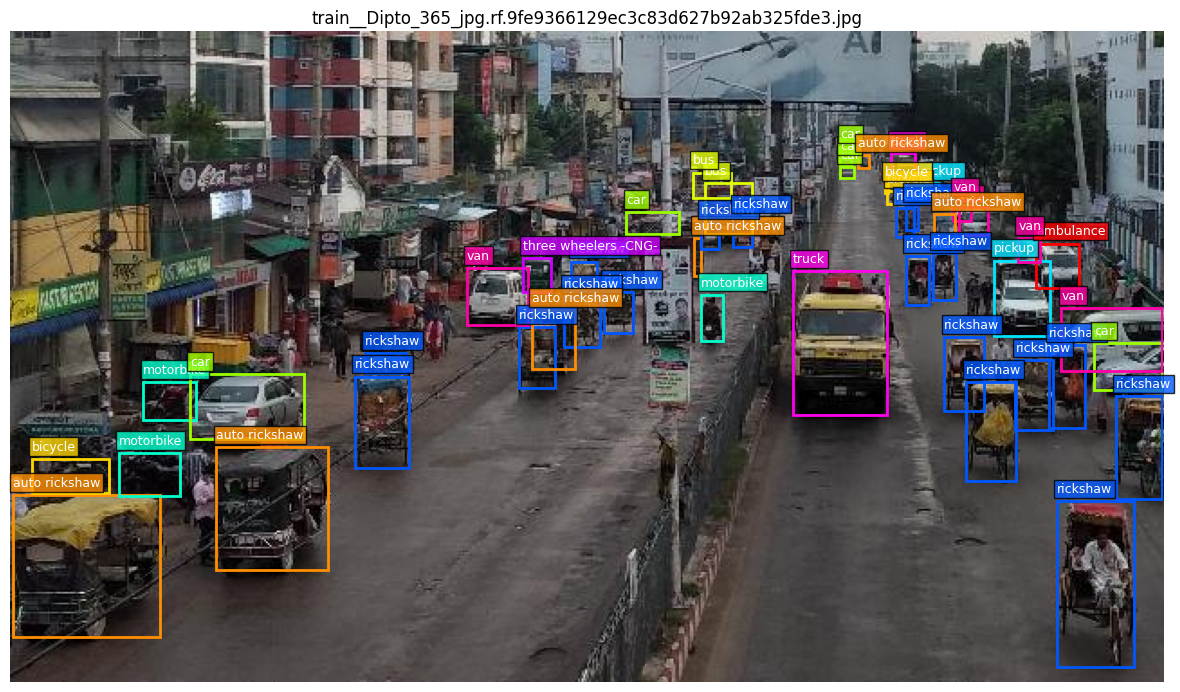

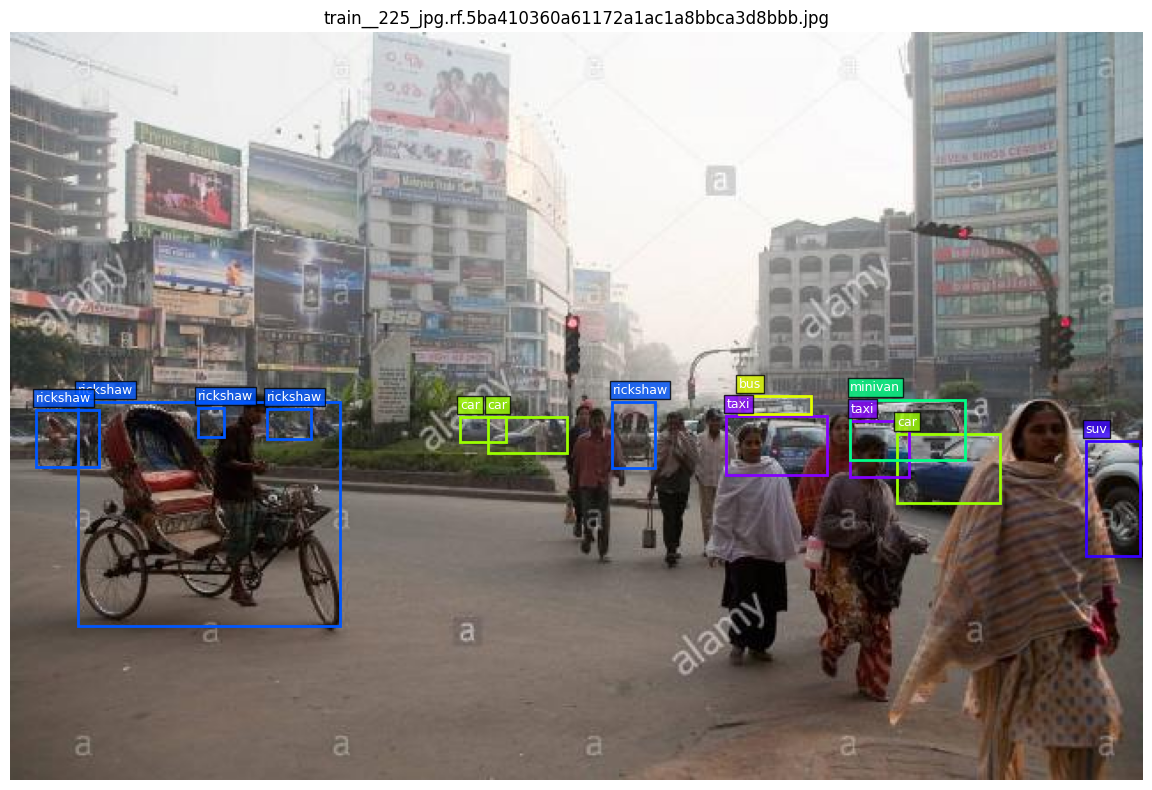

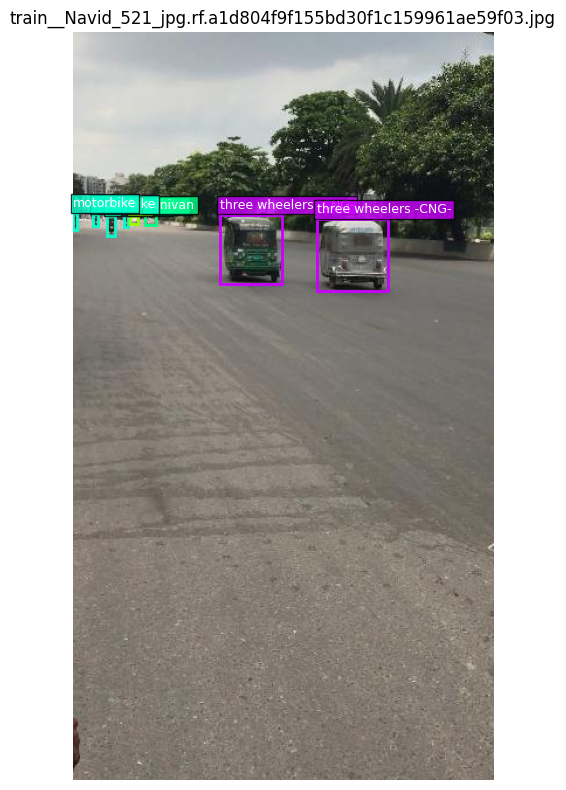

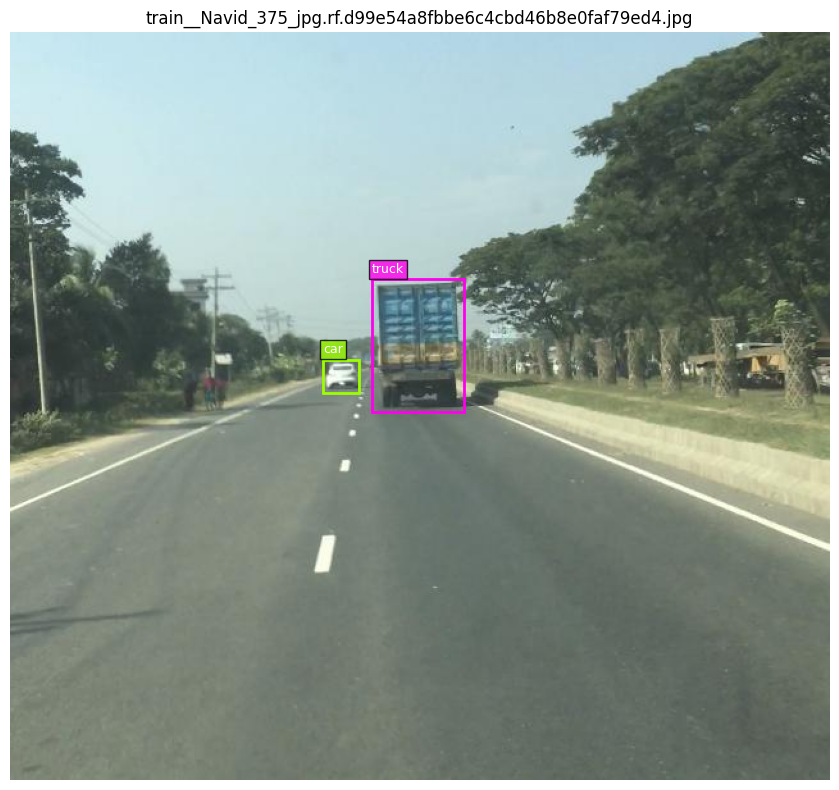

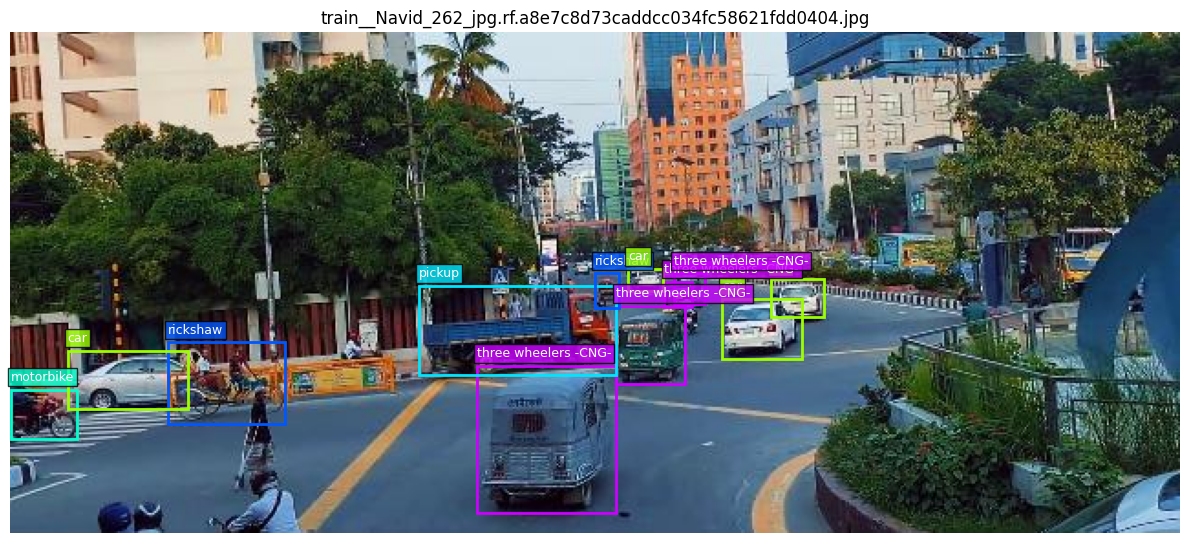

In [11]:
import matplotlib.patches as patches

def show_image_with_labels(image_path, label_path):
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    lines = Path(label_path).read_text(encoding="utf-8").splitlines()
    for line in lines:
        if not line.strip():
            continue
        class_id, x, y, w, h = line.split()
        class_id = int(class_id)
        x, y, w, h = map(float, [x, y, w, h])
        left, top = (x-w/2)*width, (y-h/2)*height
        color = plt.cm.hsv(class_id / max(NC, 1))
        ax.add_patch(patches.Rectangle(
            (left, top), w*width, h*height,
            linewidth=2, edgecolor=color, facecolor="none"
        ))
        ax.text(left, max(0, top-5), CLASS_NAMES[class_id],
                color="white", fontsize=9,
                bbox={"facecolor": color, "alpha": 0.8, "pad": 2})
    ax.set_title(Path(image_path).name)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

train_images = sorted((DATASET_ROOT / "images/train").glob("*"))
samples = random.Random(SEED).sample(train_images, min(5, len(train_images)))
for img_path in samples:
    label_path = DATASET_ROOT / "labels/train" / f"{img_path.stem}.txt"
    show_image_with_labels(img_path, label_path)


## 12. Correctifs de compatibilité (Pillow et PyTorch)

In [12]:
# Pillow récent a supprimé FreeTypeFont.getsize(). Le dépôt YOLOv9 ancien l'utilise.
plots_file = REPO / "utils" / "plots.py"
plots_text = plots_file.read_text(encoding="utf-8")
if "self.font.getsize(label)" in plots_text:
    plots_text = plots_text.replace(
        "w, h = self.font.getsize(label)",
        "left, top, right, bottom = self.font.getbbox(label)\n"
        "                w, h = right - left, bottom - top"
    )
    plots_file.write_text(plots_text, encoding="utf-8")
elif "self.font.getbbox(label)" in plots_text:
    print("Correctif Pillow déjà présent.")
else:
    print("Aucun appel getsize(label) trouvé ; vérifier utils/plots.py si l'erreur Pillow revient.")

# PyTorch 2.6+ a changé la valeur par défaut de weights_only dans torch.load.
# Dans le dépôt officiel, le chargement des checkpoints passe par models/experimental.py.
experimental_file = REPO / "models" / "experimental.py"
exp_text = experimental_file.read_text(encoding="utf-8")
if "torch.load(" in exp_text and "weights_only=False" not in exp_text:
    exp_text = exp_text.replace(
        "torch.load(",
        "torch.load(",
        1
    )
    # Modifier uniquement l'appel torch.load de la fonction attempt_load.
    exp_lines = exp_text.splitlines()
    for i, line in enumerate(exp_lines):
        if "torch.load(" in line and "weights_only" not in line:
            if line.rstrip().endswith(")"):
                exp_lines[i] = line.rstrip()[:-1] + ", weights_only=False)"
            break
    experimental_file.write_text("\n".join(exp_lines) + "\n", encoding="utf-8")

import py_compile
for file in [plots_file, experimental_file]:
    py_compile.compile(str(file), doraise=True)
    print("Syntaxe OK :", file.relative_to(REPO))

# Vérification visuelle du bloc Pillow.
for i, line in enumerate(plots_file.read_text(encoding="utf-8").splitlines(), 1):
    if "getbbox(label)" in line or "right - left" in line:
        print(f"{i}: {line}")


Syntaxe OK : utils/plots.py
Syntaxe OK : models/experimental.py
86:                 left, top, right, bottom = self.font.getbbox(label)
87:                 w, h = right - left, bottom - top  # text width, height


## 13. Configuration des entraînements

In [13]:
HYP = REPO / "data" / "hyps" / "hyp.scratch-high.yaml"
assert HYP.is_file()
COMMON = [
    "--workers", str(WORKERS),
    "--device", DEVICE,
    "--batch-size", str(BATCH_SIZE),
    "--data", str(DATA_YAML),
    "--img", str(IMG_SIZE),
    "--hyp", str(HYP),
    "--close-mosaic", "2",
]
print("Configuration prête.")
print("GPU :", DEVICE, "| batch :", BATCH_SIZE, "| image :", IMG_SIZE)


Configuration prête.
GPU : cpu | batch : 4 | image : 640


## 14. Entraînement initial YOLOv9-C (transfer learning)

In [14]:
%cd /kaggle/working/yolov9
!python train_dual.py { " ".join(COMMON) } --cfg models/detect/yolov9-c.yaml --weights yolov9-c.pt --epochs 5 --freeze 10 --name roadvision_yolov9c_transfer --project /kaggle/working/roadvision_native/runs


/venv/main/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


/kaggle/working/yolov9
/bin/bash: line 1: python: command not found


## 15. Fine-tuning YOLOv9-C

In [15]:
TRANSFER_YOLO = RUNS_ROOT / "roadvision_yolov9c_transfer" / "weights" / "best.pt"
if not TRANSFER_YOLO.is_file():
    raise FileNotFoundError(f"Checkpoint de transfert introuvable : {TRANSFER_YOLO}. Exécute d'abord la cellule 14.")
%cd /kaggle/working/yolov9
!python train_dual.py { " ".join(COMMON) } --cfg models/detect/yolov9-c.yaml --weights /kaggle/working/roadvision_native/runs/roadvision_yolov9c_transfer/weights/best.pt --epochs 15 --name roadvision_yolov9c_finetune --project /kaggle/working/roadvision_native/runs


FileNotFoundError: Checkpoint de transfert introuvable : /kaggle/working/roadvision_native/runs/roadvision_yolov9c_transfer/weights/best.pt. Exécute d'abord la cellule 14.

## 16. Entraînement initial GELAN-C (transfer learning)

In [ ]:
%cd /kaggle/working/yolov9
!python train.py { " ".join(COMMON) } --cfg models/detect/gelan-c.yaml --weights gelan-c.pt --epochs 5 --freeze 10 --name roadvision_gelanc_transfer --project /kaggle/working/roadvision_native/runs


## 17. Fine-tuning GELAN-C

In [ ]:
TRANSFER_GELAN = RUNS_ROOT / "roadvision_gelanc_transfer" / "weights" / "best.pt"
if not TRANSFER_GELAN.is_file():
    raise FileNotFoundError(f"Checkpoint de transfert introuvable : {TRANSFER_GELAN}. Exécute d'abord la cellule 16.")
%cd /kaggle/working/yolov9
!python train.py { " ".join(COMMON) } --cfg models/detect/gelan-c.yaml --weights /kaggle/working/roadvision_native/runs/roadvision_gelanc_transfer/weights/best.pt --epochs 15 --name roadvision_gelanc_finetune --project /kaggle/working/roadvision_native/runs


## 18. Évaluer YOLOv9-C sur le jeu test

In [ ]:
YOLO_BEST = RUNS_ROOT / "roadvision_yolov9c_finetune" / "weights" / "best.pt"
if not YOLO_BEST.is_file():
    raise FileNotFoundError(f"Modèle final YOLOv9-C introuvable : {YOLO_BEST}")
%cd /kaggle/working/yolov9
!python val_dual.py --data data/roadvision.yaml --img 640 --batch-size 4 --conf 0.001 --iou 0.7 --device {DEVICE} --weights /kaggle/working/roadvision_native/runs/roadvision_yolov9c_finetune/weights/best.pt --name roadvision_yolov9c_test --project /kaggle/working/roadvision_native/evaluation --task test


## 19. Évaluer GELAN-C sur le jeu test

In [ ]:
GELAN_BEST = RUNS_ROOT / "roadvision_gelanc_finetune" / "weights" / "best.pt"
if not GELAN_BEST.is_file():
    raise FileNotFoundError(f"Modèle final GELAN-C introuvable : {GELAN_BEST}")
%cd /kaggle/working/yolov9
!python val.py --data data/roadvision.yaml --img 640 --batch-size 4 --conf 0.001 --iou 0.7 --device {DEVICE} --weights /kaggle/working/roadvision_native/runs/roadvision_gelanc_finetune/weights/best.pt --name roadvision_gelanc_test --project /kaggle/working/roadvision_native/evaluation --task test


## 20. Consulter les résultats CSV

In [ ]:
results_files = sorted(set(RUNS_ROOT.rglob("results.csv")) | set(EVAL_ROOT.rglob("results.csv")))
if not results_files:
    print("Aucun results.csv trouvé pour le moment.")
for file in results_files:
    print("\nRésultats :", file)
    try:
        display(pd.read_csv(file).tail())
    except Exception as exc:
        print("Lecture impossible :", exc)


## 21. Tableau comparatif à compléter avec les métriques de test

In [ ]:
comparison = pd.DataFrame([
    {"Model": "YOLOv9-C", "Precision": None, "Recall": None, "mAP50": None, "mAP50-95": None},
    {"Model": "GELAN-C", "Precision": None, "Recall": None, "mAP50": None, "mAP50-95": None},
])
display(comparison)
comparison_path = WORK_ROOT / "model_comparison_template.csv"
comparison.to_csv(comparison_path, index=False)
print("Template enregistré :", comparison_path)


## Notes importantes

- Le notebook conserve le dataset Kaggle original en lecture seule et reconstruit le dataset dans `dataset_rebuilt`.
- À chaque nouvelle exécution de la cellule 8, le dossier `dataset_rebuilt` est supprimé puis recréé proprement. Cela évite les images résiduelles ou les doublons.
- Les images sont réparties aléatoirement avec `SEED = 42`. La répartition peut différer légèrement des nombres attendus si le nombre d'images valides change.
- Les deux entraînements initiaux doivent être terminés avant leurs phases de fine-tuning respectives.
- Les métriques finales doivent être relevées dans les sorties de validation sur `test`. Ne remplis pas le tableau avec les métriques de validation d'entraînement.
- Si Kaggle interrompt la session, vérifie les checkpoints `best.pt` avant de relancer une phase.
